# SVM lề cứng: giải bài toán tối ưu

*Bài 7, mục 7.1.2.* Bài toán tối ưu của SVM (dữ liệu tách được tuyến tính):
$$\min_{\mathbf{w}, b}\ \frac{1}{2}\|\mathbf{w}\|_2^2 \quad \text{với ràng buộc} \quad y_i(\mathbf{w}^T\mathbf{x}_i + b) \ge 1,\ i = 1, \dots, N$$
Đây là bài toán quy hoạch toàn phương (hàm mục tiêu bậc hai lồi, ràng buộc tuyến tính).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dữ liệu ví dụ 8 điểm, nhãn y thuộc {+1, -1}
X = np.array([[3, 1], [3, -1], [6, 1], [6, -1],      # lớp +1
              [1, 0], [0, 1], [0, -1], [-1, 0]], dtype=float)   # lớp -1
y = np.array([1, 1, 1, 1, -1, -1, -1, -1])

## 1. Giải trực tiếp bài toán gốc bằng `scipy.optimize.minimize`

Biến tối ưu là $\theta = (w_1, w_2, b)$.

In [2]:
from scipy.optimize import minimize


def objective(theta):
    w = theta[:2]
    return 0.5 * w @ w                       # (1/2) ||w||^2


constraints = [{'type': 'ineq', 'fun': lambda theta, i=i: y[i] * (X[i] @ theta[:2] + theta[2]) - 1}
               for i in range(len(y))]       # y_i (w^T x_i + b) - 1 >= 0
result = minimize(objective, x0=np.zeros(3), constraints=constraints, method='SLSQP')
w, b = result.x[:2], result.x[2]
print('w =', w.round(4), ' b = %.4f' % b)
print('Độ rộng lề 2/||w|| = %.4f' % (2 / np.linalg.norm(w)))

w = [1. 0.]  b = -2.0000
Độ rộng lề 2/||w|| = 2.0000


Các **vector hỗ trợ** là những điểm nằm đúng trên hai biên, tức $y_i(\mathbf{w}^T\mathbf{x}_i + b) = 1$:

In [3]:
functional_margin = y * (X @ w + b)          # y_i (w^T x_i + b)
for x_i, y_i, m in zip(X, y, functional_margin):
    print('x = %-12s y = %+d   y(w^T x + b) = %.3f %s' % (x_i, y_i, m, '<- vector hỗ trợ' if abs(m - 1) < 1e-4 else ''))

x = [3. 1.]      y = +1   y(w^T x + b) = 1.000 <- vector hỗ trợ
x = [ 3. -1.]    y = +1   y(w^T x + b) = 1.000 <- vector hỗ trợ
x = [6. 1.]      y = +1   y(w^T x + b) = 4.000 
x = [ 6. -1.]    y = +1   y(w^T x + b) = 4.000 
x = [1. 0.]      y = -1   y(w^T x + b) = 1.000 <- vector hỗ trợ
x = [0. 1.]      y = -1   y(w^T x + b) = 2.000 
x = [ 0. -1.]    y = -1   y(w^T x + b) = 2.000 
x = [-1.  0.]    y = -1   y(w^T x + b) = 3.000 


## 2. So sánh với scikit-learn

`SVC(kernel='linear')` giải bài toán đối ngẫu. Tham số `C` rất lớn tương đương SVM lề cứng (mục 7.1.2 d).

In [4]:
from sklearn.svm import SVC

svm = SVC(kernel='linear', C=1e6).fit(X, y)
print('w =', svm.coef_[0].round(4), ' b = %.4f' % svm.intercept_[0])
print('Chỉ số các vector hỗ trợ:', svm.support_)
print('Các vector hỗ trợ:\n', svm.support_vectors_)

w = [ 1.0005 -0.    ]  b = -2.0011
Chỉ số các vector hỗ trợ: [4 0 1]
Các vector hỗ trợ:
 [[ 1.  0.]
 [ 3.  1.]
 [ 3. -1.]]


## 3. Nghiệm đối ngẫu: $\mathbf{w} = \sum_{i \in \mathcal{S}} \lambda_i y_i \mathbf{x}_i$

`dual_coef_` lưu $\lambda_i y_i$ của các vector hỗ trợ. Các điểm không phải vector hỗ trợ có $\lambda_i = 0$, không ảnh hưởng tới nghiệm.

In [5]:
lambda_y = svm.dual_coef_[0]                 # lambda_i * y_i
print('lambda_i =', np.abs(lambda_y).round(4))
print('Tổng lambda_i y_i = %.4f (bằng 0)' % abs(lambda_y.sum()))
w_dual = lambda_y @ svm.support_vectors_
print('w = tổng lambda_i y_i x_i =', w_dual.round(4))

lambda_i = [0.5002 0.2501 0.2501]
Tổng lambda_i y_i = 0.0000 (bằng 0)
w = tổng lambda_i y_i x_i = [ 1.0005 -0.    ]


## 4. Bỏ các điểm không phải vector hỗ trợ: nghiệm không đổi

In [6]:
keep = svm.support_
svm_sv = SVC(kernel='linear', C=1e6).fit(X[keep], y[keep])
print('Chỉ dùng %d vector hỗ trợ: w = %s, b = %.4f' % (len(keep), svm_sv.coef_[0].round(4), svm_sv.intercept_[0]))

Chỉ dùng 3 vector hỗ trợ: w = [1.0002e+00 4.0000e-04], b = -2.0004


## 5. Hình minh họa

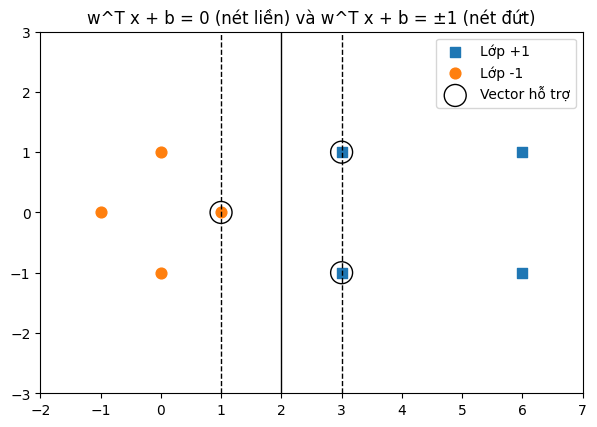

In [7]:
x1 = np.linspace(-2, 7, 2)
plt.figure(figsize=(7, 5))
plt.scatter(X[y == 1, 0], X[y == 1, 1], marker='s', s=60, label='Lớp +1')
plt.scatter(X[y == -1, 0], X[y == -1, 1], marker='o', s=60, label='Lớp -1')
plt.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1], s=250, facecolors='none', edgecolors='k', label='Vector hỗ trợ')
for level, style in [(0, '-'), (1, '--'), (-1, '--')]:
    plt.axvline((level - b) / w[0], color='k', ls=style, lw=1)    # w2 = 0 nên các đường thẳng đứng
plt.xlim(-2, 7); plt.ylim(-3, 3); plt.legend(); plt.gca().set_aspect('equal')
plt.title('w^T x + b = 0 (nét liền) và w^T x + b = ±1 (nét đứt)')
plt.show()